***RePaint Sampling on DAS Patches***
**mixed DAS PATCHES**

In [2]:
import torch
import matplotlib.pyplot as plt
import sys
sys.path.append("..")
from utils.traffic_masks import line_mask
from pathlib import Path
from utils.das_dataset import DasDataset
from torch.utils.data import DataLoader
from utils.normalizer import denormalize

In [3]:
device= "cuda" if torch.cuda.is_available() else "cpu"
mask  = line_mask(h=256, w=512, s=(100,60), e=(400,150), r=4, device=device)
print(mask.shape, mask.device)

torch.Size([256, 512]) cuda:0


In [4]:
das_data = Path("/datasets/training/earthquake/share/SISSLE_south30")
train_files_traffic_e = [das_data/"train_1111.h5"]
test_files_traffic_e = [das_data/"test_1111.h5"]

device= "cuda" if torch.cuda.is_available() else "cpu"

train_set_traffic_e = DasDataset(train_files_traffic_e)
test_set_traffic_e = DasDataset(test_files_traffic_e)
train_loader_traffic_e = DataLoader(train_set_traffic_e, batch_size=16, shuffle=True)
test_loader_traffic_e = DataLoader(test_set_traffic_e, batch_size=16, shuffle=False)

In [5]:
batch = next(iter(train_loader_traffic_e))
patch = batch [0:1].to(device)
print(patch.shape)

torch.Size([1, 1, 256, 512])


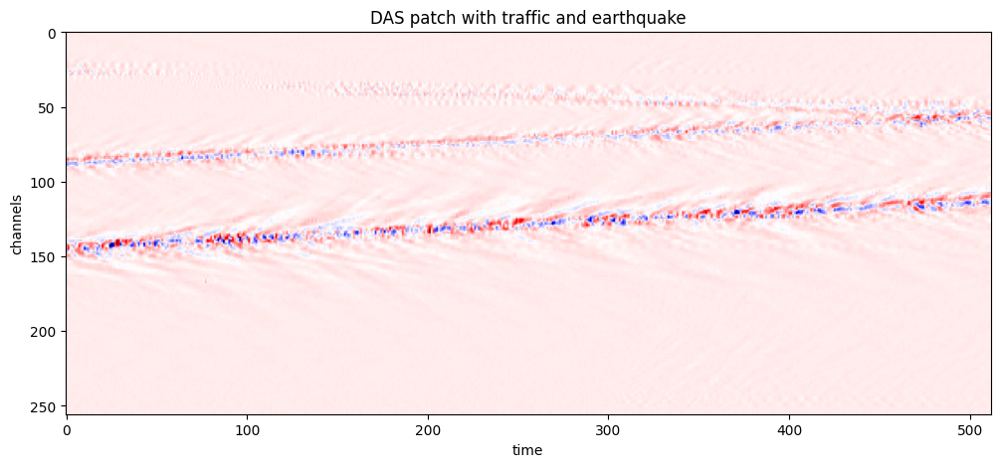

-18886.8203125 17503.234375


In [ ]:
patch_denorm = denormalize(patch)

plt.figure(figsize=(12,5))
image=plt.imshow(patch_denorm[0,0].detach().cpu(), cmap="seismic", aspect="auto")
vmin, vmax = image.get_clim()
plt.xlabel("time")
plt.ylabel("channels")
plt.title("DAS patch with traffic and earthquake")
plt.show()
print(vmin, vmax)

In [6]:
example = torch.load("data/repaint_examples/traffic_exp_01.pt", map_location=device)
patch = example["patch"].to(device)
print(patch.shape)

torch.Size([1, 1, 256, 512])


In [7]:
import importlib
import utils.traffic_masks
importlib.reload(utils.traffic_masks)
from utils.traffic_masks import line_mask

**STANDARD MSE MAMBA mixed**
*(mistake : unshuffled loaders)*

In [8]:
from models.unet_mamba import DDPM
from utils.noise_scheduler import LinearNoiseScheduler
model_mb=  DDPM(in_channels=1, out_channels=1, base_channels=64, channels_multiplier=(1,1,2,2,4),
                  nbr_rb=2, dropout=0.1).to(device)
checkpoints=Path("checkpoints")
model_mb_path= Path(checkpoints)/"das_ddpm_earthquake_model_mamba_50_50_mixed_normal_mse_c.pth"
checkpoint_model_mb = torch.load(model_mb_path, map_location = device)
model_mb.load_state_dict(checkpoint_model_mb["model_mb"])

<All keys matched successfully>

In [9]:
scheduler_E = LinearNoiseScheduler(timesteps=1000, beta_start=1e-4,beta_end=0.02, device=device)

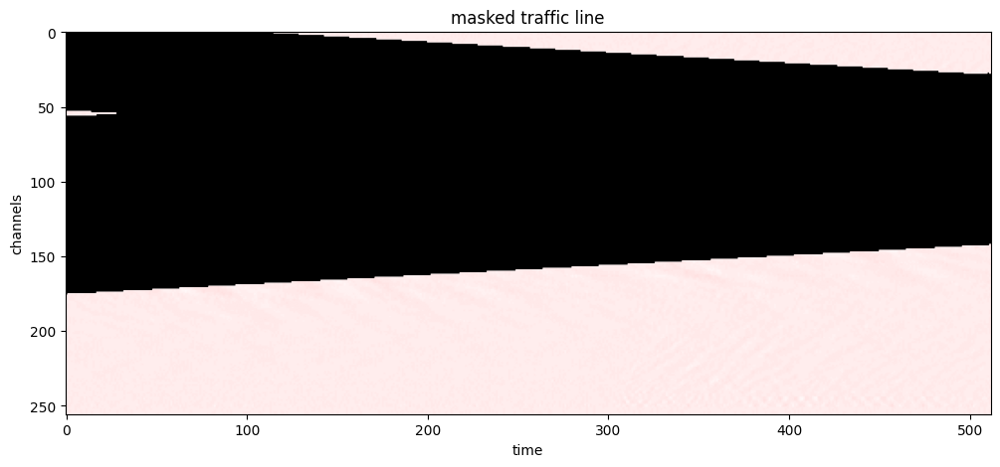

In [10]:
vmin = -18886.82
vmax = 17503.23
mask1  = line_mask(h=256, w=512, s=(0,145), e=(510,112), r=30, device=device)
mask2  = line_mask(h=256, w=512, s=(0,86), e=(510,57), r=30, device=device)
mask3  = line_mask(h=256, w=512, s=(0,22), e=(510,58), r=30, device=device)
mask_all = mask1*mask2*mask3
mask_all = mask_all.unsqueeze(0). unsqueeze(0)
missing_region = (mask_all[0,0] == 0).detach().cpu()
masked_patch = patch * mask_all
plt.figure(figsize=(12,5))
plt.imshow(denormalize(masked_patch)[0,0].detach().cpu(), cmap="seismic", aspect="auto", vmin=vmin, vmax=vmax)
plt.imshow(missing_region, cmap="gray_r", aspect="auto", alpha = missing_region.float())
plt.xlabel("time")
plt.ylabel("channels")
plt.title("masked traffic line")
plt.show()

torch.Size([1, 1, 256, 512])


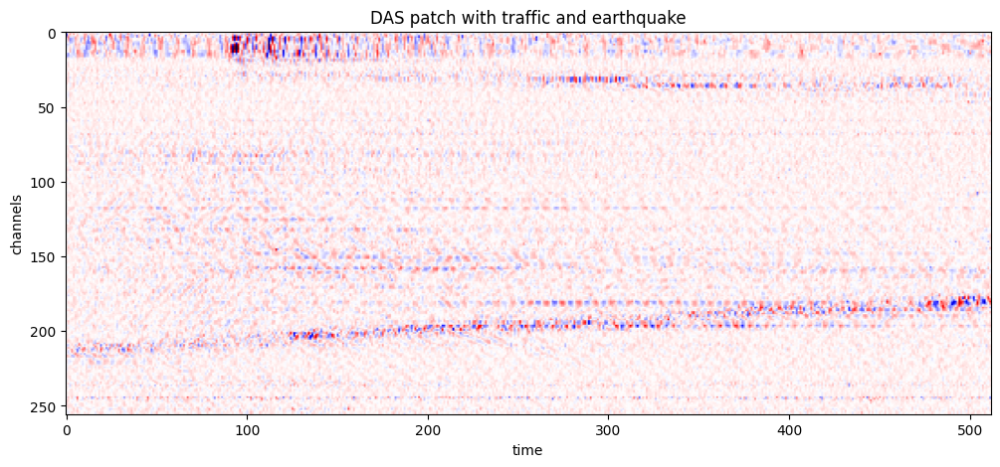

-8317.486328125 7938.90673828125


In [20]:
batch = next(iter(train_loader_traffic_e))
patch = batch [0:1].to(device)
print(patch.shape)
patch_denorm = denormalize(patch)

plt.figure(figsize=(12,5))
image=plt.imshow(patch_denorm[0,0].detach().cpu(), cmap="seismic", aspect="auto")
vmin, vmax = image.get_clim()
plt.xlabel("time")
plt.ylabel("channels")
plt.title("DAS patch with traffic and earthquake")
plt.show()
print(vmin, vmax)

In [45]:
example2 = torch.load("data/repaint_examples/traffic_exp_02.pt", map_location=device)
patch2 = example2["patch"].to(device)
print(patch2.shape)

torch.Size([1, 1, 256, 512])


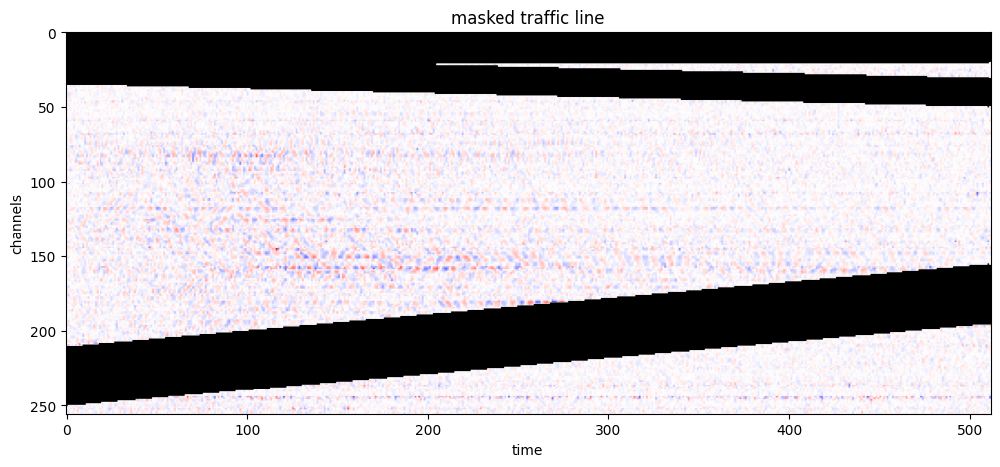

In [50]:
vmin = -8000
vmax = 8000
mask1  = line_mask(h=256, w=512, s=(0,230), e=(510,175), r=20, device=device)
mask2  = line_mask(h=256, w=512, s=(0,25), e=(510,40), r=10, device=device)
mask3  = line_mask(h=256, w=512, s=(0,5), e=(510,5), r=15, device=device)
mask_all = mask1*mask2*mask3
mask_all = mask_all.unsqueeze(0). unsqueeze(0)
missing_region = (mask_all[0,0] == 0).detach().cpu()
masked_patch2 = patch2 * mask_all
plt.figure(figsize=(12,5))
plt.imshow(denormalize(masked_patch)[0,0].detach().cpu(), cmap="seismic", aspect="auto", vmin=vmin, vmax=vmax)
plt.imshow(missing_region, cmap="gray_r", aspect="auto", alpha = missing_region.float())
plt.xlabel("time")
plt.ylabel("channels")
plt.title("masked traffic line")
plt.show()

**test on earthquake patch**

In [12]:
train_files_traffic_e0 = [das_data/"train_1001.h5"]
test_files_traffic_e0 = [das_data/"test_1001.h5"]

device= "cuda" if torch.cuda.is_available() else "cpu"

train_set_traffic_e0 = DasDataset(train_files_traffic_e0)
test_set_traffic_e0 = DasDataset(test_files_traffic_e0)
train_loader_traffic_e0 = DataLoader(train_set_traffic_e0, batch_size=16, shuffle=True)
test_loader_traffic_e0 = DataLoader(test_set_traffic_e0, batch_size=16, shuffle=False)

In [11]:
batch0 = next(iter(train_loader_traffic_e0))
patch0 = batch0 [0:1].to(device)
print(patch0.shape)

torch.Size([1, 1, 256, 512])


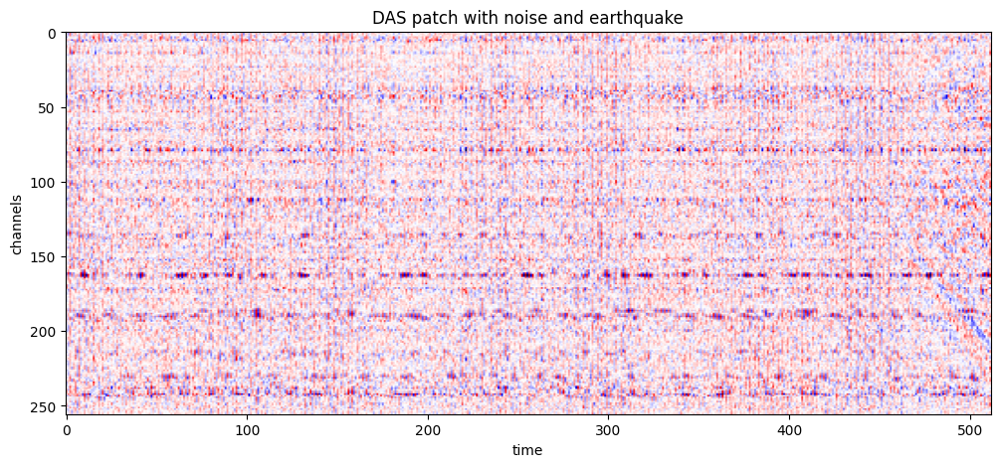

-409.0985412597656 386.85205078125


In [61]:
patch_denorm0 = denormalize(patch0)

plt.figure(figsize=(12,5))
image=plt.imshow(patch_denorm0[0,0].detach().cpu(), cmap="seismic", aspect="auto")
vmin0, vmax0 = image.get_clim()
plt.xlabel("time")
plt.ylabel("channels")
plt.title("DAS patch with noise and earthquake")
plt.show()
print(vmin0, vmax0)

In [13]:
example3 = torch.load("data/repaint_examples/earthquake_exp_01.pt", map_location=device)
patch3 = example3["patch"].to(device)
print(patch3.shape)

torch.Size([1, 1, 256, 512])


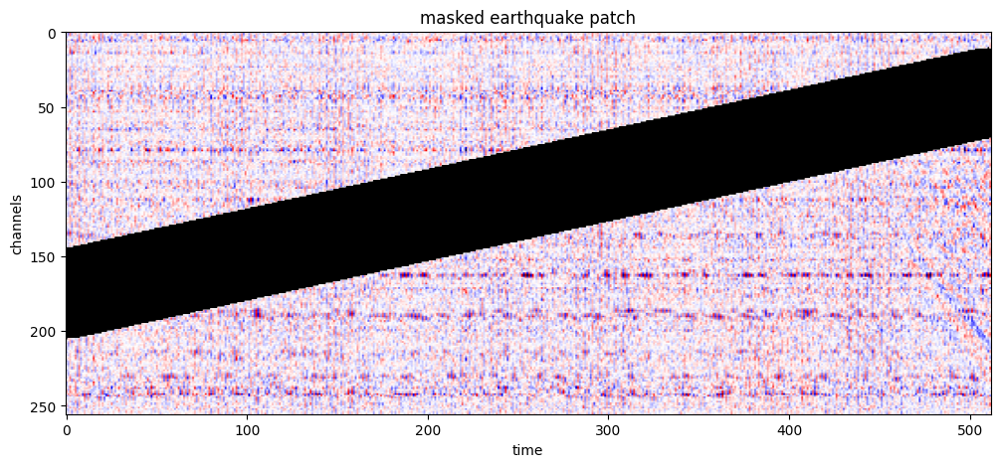

In [14]:
vmin0 = -400
vmax0 = 400
mask0  = line_mask(h=256, w=512, s=(0,175), e=(510,40), r=30, device=device)
missing_region0 = (mask0== 0).detach().cpu()
masked_patch3 = patch3 * mask0
plt.figure(figsize=(12,5))
plt.imshow(denormalize(masked_patch3)[0,0].detach().cpu(), cmap="seismic", aspect="auto", vmin=vmin0, vmax=vmax0)
plt.imshow(missing_region0, cmap="gray_r", aspect="auto", alpha = missing_region0.float())
plt.xlabel("time")
plt.ylabel("channels")
plt.title("masked earthquake patch")
plt.show()

**Repaint with a jumping schedule**

In [15]:
import importlib
import utils.repaint as repaint
importlib.reload(repaint)

<module 'utils.repaint' from '/home/islem.dhouioui/ddpm/notebooks/../utils/repaint.py'>

In [12]:
times=repaint.repaint_schedule(10,1,3)
print(times)

[9, 8, 9, 8, 9, 8, 7, 8, 7, 8, 7, 6, 7, 6, 7, 6, 5, 6, 5, 6, 5, 4, 5, 4, 5, 4, 3, 4, 3, 4, 3, 2, 3, 2, 3, 2, 1, 2, 1, 2, 1, 0, 1, 0, 1, 0, -1]


jump_length=1, jump_n_sample=3

In [16]:
seed = 42
torch.manual_seed(seed)
torch.cuda.manual_seed_all(seed)
result4, snaps4, times4 = repaint.sample_repaint(model=model_mb, scheduler=scheduler_E, x0=patch3, mask=mask0,
                                                 jump_length=1, jump_n_sample=3, steps_to_save=[999, 600, 300, 100, 0])

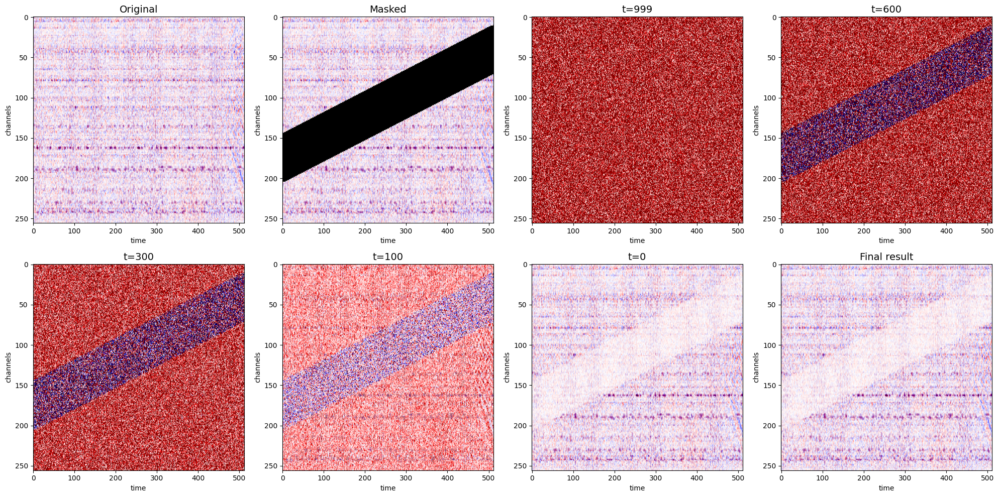

In [17]:
steps_to_show = [999, 600, 300, 100, 0]

patch_denorm = denormalize(patch3)
masked_denorm = denormalize(masked_patch3)
result_denorm = denormalize(result4)

fig, axes = plt.subplots(2,4,figsize=(20, 10))
axes = axes.flatten()
axes[0].imshow(patch_denorm[0,0].detach().cpu(),cmap="seismic",aspect="auto",vmin=vmin0,vmax=vmax0)
axes[0].set_title("Original", fontsize=14)

axes[1].imshow(masked_denorm[0,0].detach().cpu(),cmap="seismic",aspect="auto",vmin=vmin0,vmax=vmax0)

axes[1].imshow(missing_region0,cmap="gray_r",aspect="auto",alpha=missing_region0.float())

axes[1].set_title("Masked", fontsize=14)

for i, step in enumerate(snaps4):

    snap_denorm = denormalize(snaps4[step])

    axes[i+2].imshow(snap_denorm[0,0].detach().cpu(),cmap="seismic",aspect="auto",vmin=vmin0,vmax=vmax0)

    axes[i+2].set_title(f"t={step}",fontsize=14)

axes[7].imshow(result_denorm[0,0].detach().cpu(),cmap="seismic",aspect="auto",vmin=vmin0,vmax=vmax0)

axes[7].set_title("Final result",fontsize=14)

for ax in axes:
    ax.set_xlabel("time")
    ax.set_ylabel("channels")

plt.tight_layout()
plt.show()

jump_length=1, jump_n_sample=10

In [18]:
seed = 42
torch.manual_seed(seed)
torch.cuda.manual_seed_all(seed)
result5, snaps5, times5 = repaint.sample_repaint(model=model_mb, scheduler=scheduler_E, x0=patch3, mask=mask0,
                                                 jump_length=1, jump_n_sample=10, steps_to_save=[999, 600, 300, 100, 0])

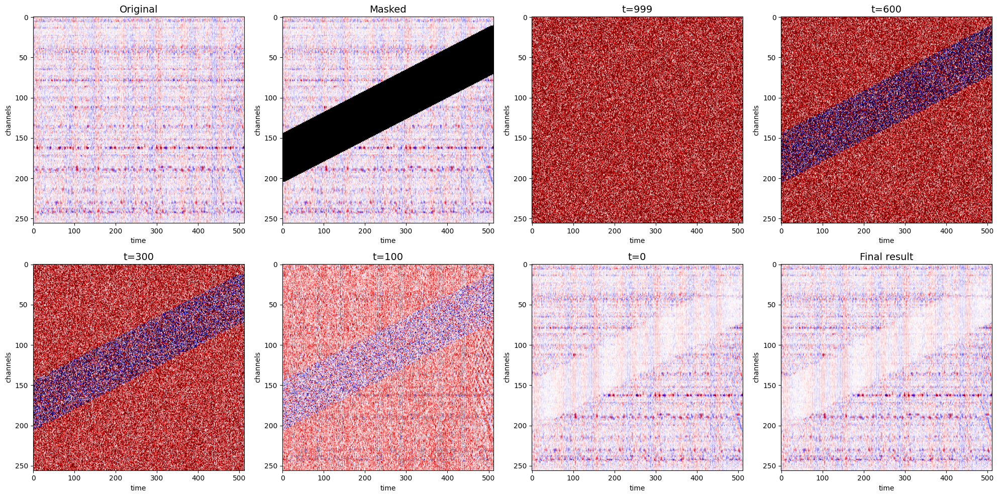

In [19]:
steps_to_show = [999, 600, 300, 100, 0]

patch_denorm = denormalize(patch3)
masked_denorm = denormalize(masked_patch3)
result_denorm = denormalize(result5)

fig, axes = plt.subplots(2,4,figsize=(20, 10))
axes = axes.flatten()
axes[0].imshow(patch_denorm[0,0].detach().cpu(),cmap="seismic",aspect="auto",vmin=vmin0,vmax=vmax0)
axes[0].set_title("Original", fontsize=14)

axes[1].imshow(masked_denorm[0,0].detach().cpu(),cmap="seismic",aspect="auto",vmin=vmin0,vmax=vmax0)

axes[1].imshow(missing_region0,cmap="gray_r",aspect="auto",alpha=missing_region0.float())

axes[1].set_title("Masked", fontsize=14)

for i, step in enumerate(snaps5):

    snap_denorm = denormalize(snaps5[step])

    axes[i+2].imshow(snap_denorm[0,0].detach().cpu(),cmap="seismic",aspect="auto",vmin=vmin0,vmax=vmax0)

    axes[i+2].set_title(f"t={step}",fontsize=14)

axes[7].imshow(result_denorm[0,0].detach().cpu(),cmap="seismic",aspect="auto",vmin=vmin0,vmax=vmax0)

axes[7].set_title("Final result",fontsize=14)

for ax in axes:
    ax.set_xlabel("time")
    ax.set_ylabel("channels")

plt.tight_layout()
plt.show()

jump_length=1, jump_n_sample=20

In [31]:
seed = 42
torch.manual_seed(seed)
torch.cuda.manual_seed_all(seed)
result6, snaps6, times6 = repaint.sample_repaint(model=model_mb, scheduler=scheduler_E, x0=patch3, mask=mask0,
                                                 jump_length=1, jump_n_sample=50, steps_to_save=[999, 600, 300, 100, 0])

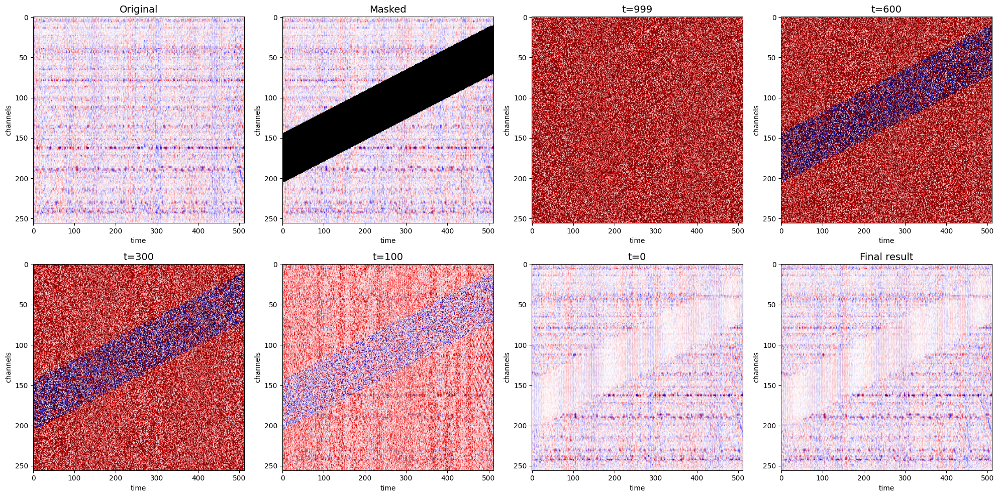

In [ ]:
steps_to_show = [999, 600, 300, 100, 0]

patch_denorm = denormalize(patch3)
masked_denorm = denormalize(masked_patch3)
result_denorm = denormalize(result6)

fig, axes = plt.subplots(2,4,figsize=(20, 10))
axes = axes.flatten()
axes[0].imshow(patch_denorm[0,0].detach().cpu(),cmap="seismic",aspect="auto",vmin=vmin0,vmax=vmax0)
axes[0].set_title("Original", fontsize=14)

axes[1].imshow(masked_denorm[0,0].detach().cpu(),cmap="seismic",aspect="auto",vmin=vmin0,vmax=vmax0)

axes[1].imshow(missing_region0,cmap="gray_r",aspect="auto",alpha=missing_region0.float())

axes[1].set_title("Masked", fontsize=14)

for i, step in enumerate(snaps6):

    snap_denorm = denormalize(snaps6[step])

    axes[i+2].imshow(snap_denorm[0,0].detach().cpu(),cmap="seismic",aspect="auto",vmin=vmin0,vmax=vmax0)

    axes[i+2].set_title(f"t={step}",fontsize=14)

axes[7].imshow(result_denorm[0,0].detach().cpu(),cmap="seismic",aspect="auto",vmin=vmin0,vmax=vmax0)

axes[7].set_title("Final result",fontsize=14)

for ax in axes:
    ax.set_xlabel("time")
    ax.set_ylabel("channels")

plt.tight_layout()
plt.show()

**Mamba 50/50 Model on traffic+earthquake**

In [63]:
seed = 42
torch.manual_seed(seed)
torch.cuda.manual_seed_all(seed)
result10, snaps10, times10 = repaint.sample_repaint(model=model_mb, scheduler=scheduler_E, x0=patch2, mask=mask_all,
                                                 jump_length=1, jump_n_sample=10, steps_to_save=[999, 600, 300, 100, 0])

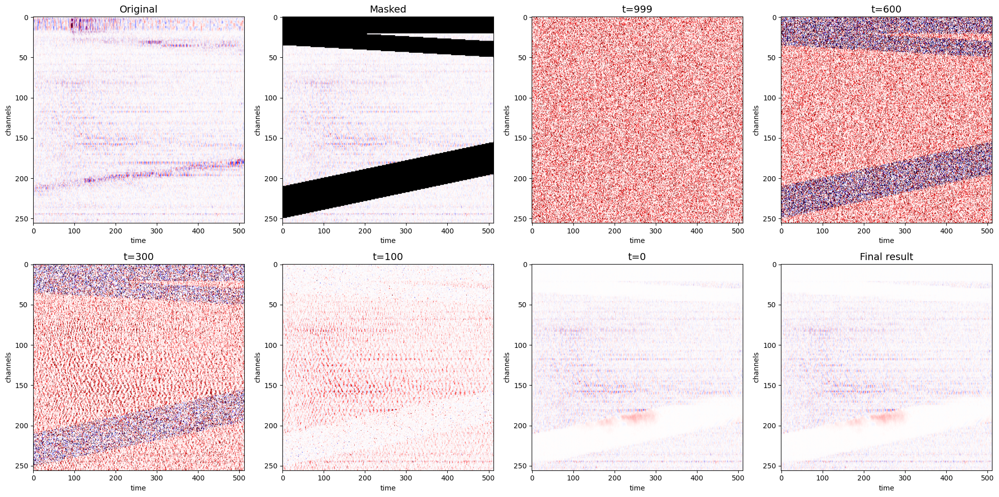

In [64]:
steps_to_show = [999, 600, 300, 100, 0]

patch_denorm = denormalize(patch2)
masked_denorm = denormalize(masked_patch2)
result_denorm = denormalize(result10)

fig, axes = plt.subplots(2,4,figsize=(20, 10))
axes = axes.flatten()
axes[0].imshow(patch_denorm[0,0].detach().cpu(),cmap="seismic",aspect="auto",vmin=vmin,vmax=vmax)
axes[0].set_title("Original", fontsize=14)

axes[1].imshow(masked_denorm[0,0].detach().cpu(),cmap="seismic",aspect="auto",vmin=vmin,vmax=vmax)

axes[1].imshow(missing_region,cmap="gray_r",aspect="auto",alpha=missing_region.float())

axes[1].set_title("Masked", fontsize=14)

for i, step in enumerate(snaps10):

    snap_denorm = denormalize(snaps10[step])

    axes[i+2].imshow(snap_denorm[0,0].detach().cpu(),cmap="seismic",aspect="auto",vmin=vmin,vmax=vmax)

    axes[i+2].set_title(f"t={step}",fontsize=14)

axes[7].imshow(result_denorm[0,0].detach().cpu(),cmap="seismic",aspect="auto",vmin=vmin,vmax=vmax)

axes[7].set_title("Final result",fontsize=14)

for ax in axes:
    ax.set_xlabel("time")
    ax.set_ylabel("channels")

plt.tight_layout()
plt.show()

**SPCII MODEL WITH REPAINT ON JUMPING SCHEDULE**

In [33]:
from models.unet_spcii import DDPM
from utils.noise_scheduler import LinearNoiseScheduler
model_spcii=  DDPM(in_channels=1, out_channels=1, base_channels=64, channels_multiplier=(1,1,2,2,4),
                  nbr_rb=2, dropout=0.1).to(device)
checkpoints=Path("checkpoints")
model_spcii_path= Path(checkpoints)/"das_ddpm_earthquake_model_spcii.pth"
checkpoint_model_spcii = torch.load(model_mb_path, map_location = device)
model_spcii.load_state_dict(checkpoint_model_spcii["model_earthquake_spcii"])


<All keys matched successfully>

jump_length=1, jump_n_sample=3

In [34]:
seed = 42
torch.manual_seed(seed)
torch.cuda.manual_seed_all(seed)
result7, snaps7, times7 = repaint.sample_repaint(model=model_spcii, scheduler=scheduler_E, x0=patch3, mask=mask0,
                                                 jump_length=1, jump_n_sample=3, steps_to_save=[999, 600, 300, 100, 0])

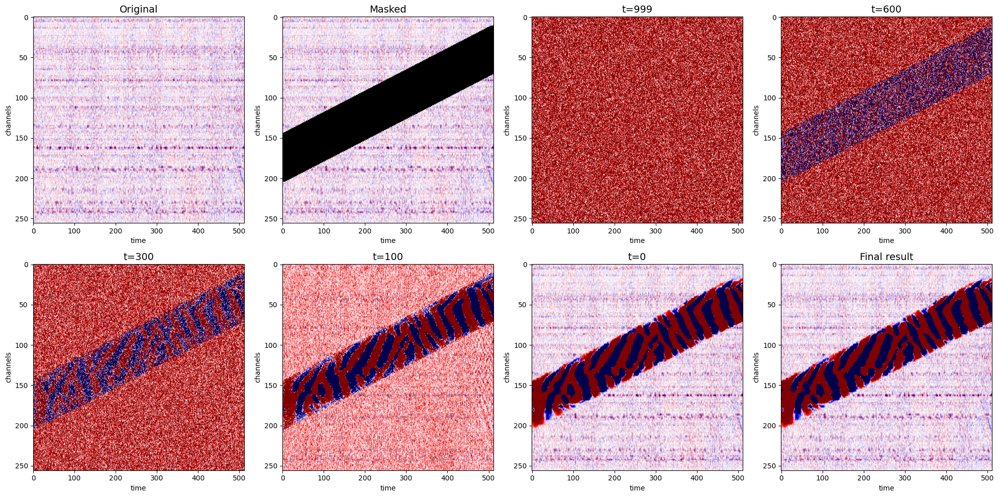

In [35]:
steps_to_show = [999, 600, 300, 100, 0]

patch_denorm = denormalize(patch3)
masked_denorm = denormalize(masked_patch3)
result_denorm = denormalize(result7)

fig, axes = plt.subplots(2,4,figsize=(20, 10))
axes = axes.flatten()
axes[0].imshow(patch_denorm[0,0].detach().cpu(),cmap="seismic",aspect="auto",vmin=vmin0,vmax=vmax0)
axes[0].set_title("Original", fontsize=14)

axes[1].imshow(masked_denorm[0,0].detach().cpu(),cmap="seismic",aspect="auto",vmin=vmin0,vmax=vmax0)

axes[1].imshow(missing_region0,cmap="gray_r",aspect="auto",alpha=missing_region0.float())

axes[1].set_title("Masked", fontsize=14)

for i, step in enumerate(snaps7):

    snap_denorm = denormalize(snaps7[step])

    axes[i+2].imshow(snap_denorm[0,0].detach().cpu(),cmap="seismic",aspect="auto",vmin=vmin0,vmax=vmax0)

    axes[i+2].set_title(f"t={step}",fontsize=14)

axes[7].imshow(result_denorm[0,0].detach().cpu(),cmap="seismic",aspect="auto",vmin=vmin0,vmax=vmax0)

axes[7].set_title("Final result",fontsize=14)

for ax in axes:
    ax.set_xlabel("time")
    ax.set_ylabel("channels")

plt.tight_layout()
plt.show()

jump_length=1, jum_n_sample=1

In [ ]:
seed = 42
torch.manual_seed(seed)
torch.cuda.manual_seed_all(seed)
result8, snaps8, times8 = repaint.sample_repaint(model=model_spcii, scheduler=scheduler_E, x0=patch3, mask=mask0,
                                                 jump_length=1, jump_n_sample=1, steps_to_save=[999, 600, 300, 100, 0])

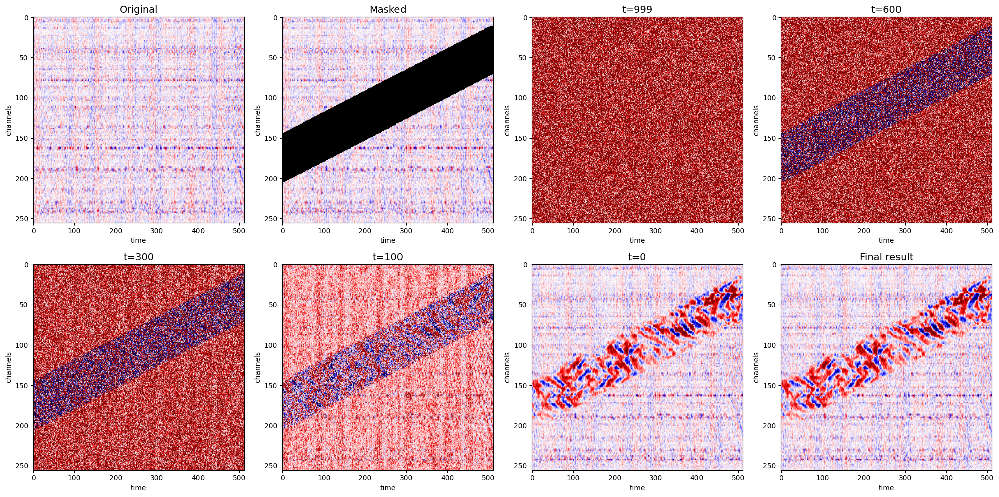

In [18]:
steps_to_show = [999, 600, 300, 100, 0]

patch_denorm = denormalize(patch3)
masked_denorm = denormalize(masked_patch3)
result_denorm = denormalize(result8)

fig, axes = plt.subplots(2,4,figsize=(20, 10))
axes = axes.flatten()
axes[0].imshow(patch_denorm[0,0].detach().cpu(),cmap="seismic",aspect="auto",vmin=vmin0,vmax=vmax0)
axes[0].set_title("Original", fontsize=14)

axes[1].imshow(masked_denorm[0,0].detach().cpu(),cmap="seismic",aspect="auto",vmin=vmin0,vmax=vmax0)

axes[1].imshow(missing_region0,cmap="gray_r",aspect="auto",alpha=missing_region0.float())

axes[1].set_title("Masked", fontsize=14)

for i, step in enumerate(snaps8):

    snap_denorm = denormalize(snaps8[step])

    axes[i+2].imshow(snap_denorm[0,0].detach().cpu(),cmap="seismic",aspect="auto",vmin=vmin0,vmax=vmax0)

    axes[i+2].set_title(f"t={step}",fontsize=14)

axes[7].imshow(result_denorm[0,0].detach().cpu(),cmap="seismic",aspect="auto",vmin=vmin0,vmax=vmax0)

axes[7].set_title("Final result",fontsize=14)

for ax in axes:
    ax.set_xlabel("time")
    ax.set_ylabel("channels")

plt.tight_layout()
plt.show()

**30/70 Mamba model**

In [37]:
from models.unet_mamba import DDPM
from utils.noise_scheduler import LinearNoiseScheduler
model_mb3=  DDPM(in_channels=1, out_channels=1, base_channels=64, channels_multiplier=(1,1,2,2,4),
                  nbr_rb=2, dropout=0.1).to(device)
checkpoints=Path("checkpoints")
model_mb_path= Path(checkpoints)/"das_ddpm_earthquake_model_mamba_70_30_mixed_normal_mse.pth"
checkpoint_model_mb = torch.load(model_mb_path, map_location = device)
model_mb.load_state_dict(checkpoint_model_mb["model_mb"])

<All keys matched successfully>

In [43]:
seed = 42
torch.manual_seed(seed)
torch.cuda.manual_seed_all(seed)
result9, snaps9, times9 = repaint.sample_repaint(model=model_mb3, scheduler=scheduler_E, x0=patch3, mask=mask0,
                                                 jump_length=3, jump_n_sample=10, steps_to_save=[999, 600, 300, 100, 0])

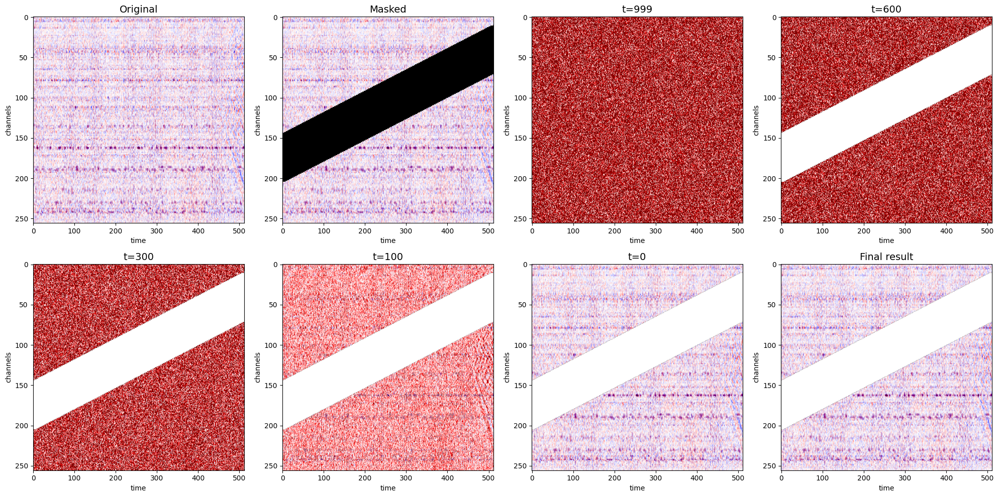

In [ ]:
steps_to_show = [999, 600, 300, 100, 0]

patch_denorm = denormalize(patch3)
masked_denorm = denormalize(masked_patch3)
result_denorm = denormalize(result9)

fig, axes = plt.subplots(2,4,figsize=(20, 10))
axes = axes.flatten()
axes[0].imshow(patch_denorm[0,0].detach().cpu(),cmap="seismic",aspect="auto",vmin=vmin0,vmax=vmax0)
axes[0].set_title("Original", fontsize=14)

axes[1].imshow(masked_denorm[0,0].detach().cpu(),cmap="seismic",aspect="auto",vmin=vmin0,vmax=vmax0)

axes[1].imshow(missing_region0,cmap="gray_r",aspect="auto",alpha=missing_region0.float())

axes[1].set_title("Masked", fontsize=14)

for i, step in enumerate(snaps9):

    snap_denorm = denormalize(snaps9[step])

    axes[i+2].imshow(snap_denorm[0,0].detach().cpu(),cmap="seismic",aspect="auto",vmin=vmin0,vmax=vmax0)

    axes[i+2].set_title(f"t={step}",fontsize=14)

axes[7].imshow(result_denorm[0,0].detach().cpu(),cmap="seismic",aspect="auto",vmin=vmin0,vmax=vmax0)

axes[7].set_title("Final result",fontsize=14)

for ax in axes:
    ax.set_xlabel("time")
    ax.set_ylabel("channels")

plt.tight_layout()
plt.show()

In [65]:
train_files_noise = [das_data/"train_1000.h5"]
test_files_noise = [das_data/"test_1000.h5"]

device= "cuda" if torch.cuda.is_available() else "cpu"

train_set_noise = DasDataset(train_files_noise)
test_set_noise = DasDataset(test_files_noise)
train_loader_noise = DataLoader(train_set_noise, batch_size=16, shuffle=True)
test_loader_noise = DataLoader(test_set_noise, batch_size=16, shuffle=False)

torch.Size([1, 1, 256, 512])


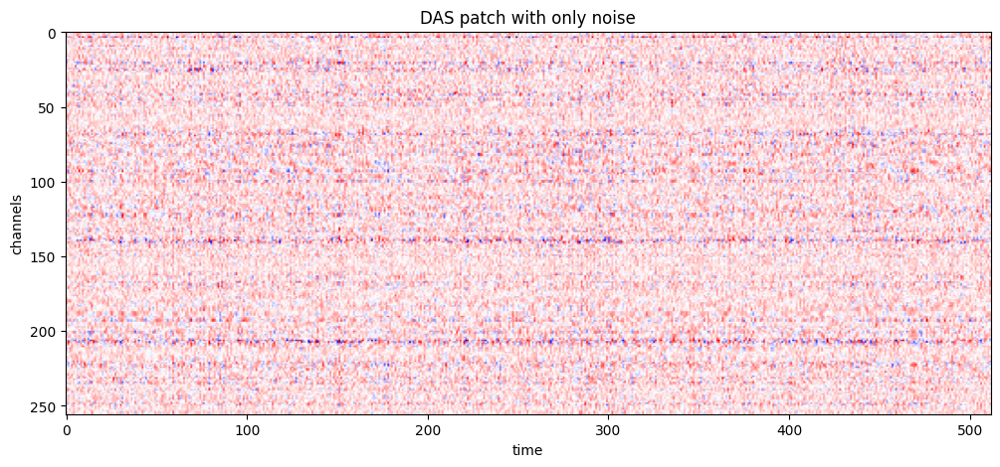

-769.1277465820312 683.9960327148438


In [68]:
batch_n = next(iter(train_loader_noise))
patch_n = batch_n [0:1].to(device)
print(patch_n.shape)
patch_denorm_n = denormalize(patch_n)

plt.figure(figsize=(12,5))
image_n=plt.imshow(patch_denorm_n[0,0].detach().cpu(), cmap="seismic", aspect="auto")
vmin_n, vmax_n = image_n.get_clim()
plt.xlabel("time")
plt.ylabel("channels")
plt.title("DAS patch with only noise")
plt.show()
print(vmin_n, vmax_n)

In [78]:
example_dir = Path("data/repaint_examples")
example_dir.mkdir(parents=True, exist_ok=True)
torch.save({"patch": patch_n.detach().cpu(),
            "desc": "Example for inpainting with only noise"},
            example_dir/"noise_exp_05.pt")

In [79]:
example_n = torch.load("data/repaint_examples/noise_exp_05.pt", map_location=device)
patch_n = example_n["patch"].to(device)
print(patch_n.shape)

torch.Size([1, 1, 256, 512])


In [93]:
mask_n = line_mask(h=256, w=512, s=(0,175), e=(510,40), r=10, device=device)
masked_patch_n = patch_n * mask_n

In [94]:
seed = 42
torch.manual_seed(seed)
torch.cuda.manual_seed_all(seed)
result_n, snaps_n, times_n = repaint.sample_repaint(model=model_mb, scheduler=scheduler_E, x0=patch_n, mask=mask_n,
                                                 jump_length=3, jump_n_sample=10, steps_to_save=[999, 600, 300, 100, 0])

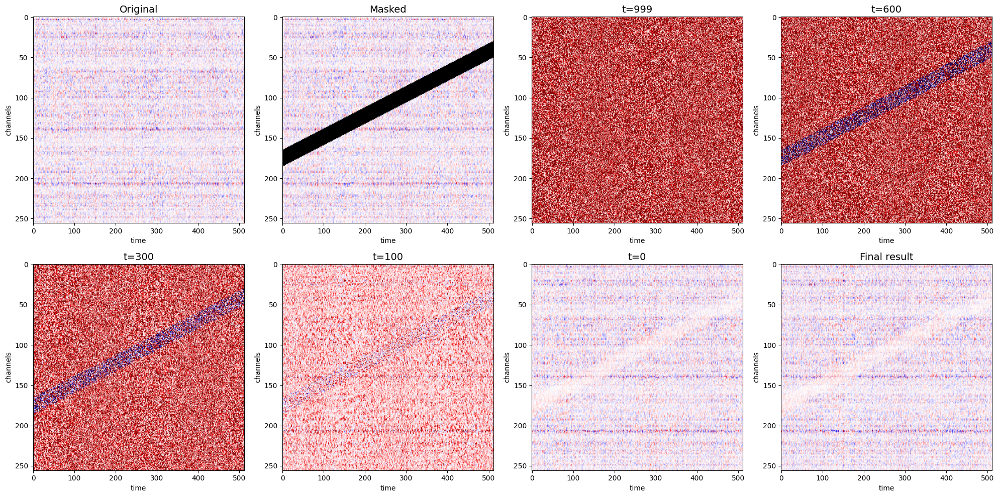

In [103]:
steps_to_show = [999, 600, 300, 100, 0]

patch_denorm_n = denormalize(patch_n)
masked_denorm_n = denormalize(masked_patch_n)
result_denorm_n = denormalize(result_n)
missing_region_n = (mask_n == 0).detach().cpu()

fig, axes = plt.subplots(2,4,figsize=(20, 10))
axes = axes.flatten()
axes[0].imshow(patch_denorm_n[0,0].detach().cpu(),cmap="seismic",aspect="auto",vmin=vmin_n,vmax=vmax_n)
axes[0].set_title("Original", fontsize=14)

axes[1].imshow(masked_denorm_n[0,0].detach().cpu(),cmap="seismic",aspect="auto",vmin=vmin_n,vmax=vmax_n)

axes[1].imshow(missing_region0,cmap="gray_r",aspect="auto",alpha=missing_region_n.float())

axes[1].set_title("Masked", fontsize=14)

for i, step in enumerate(snaps_n):

    snap_denorm_n = denormalize(snaps_n[step])

    axes[i+2].imshow(snap_denorm_n[0,0].detach().cpu(),cmap="seismic",aspect="auto",vmin=vmin_n,vmax=vmax_n)

    axes[i+2].set_title(f"t={step}",fontsize=14)

axes[7].imshow(result_denorm_n[0,0].detach().cpu(),cmap="seismic",aspect="auto",vmin=vmin_n,vmax=vmax_n)

axes[7].set_title("Final result",fontsize=14)

for ax in axes:
    ax.set_xlabel("time")
    ax.set_ylabel("channels")

plt.tight_layout()
plt.show()

In [97]:
mask_n1 = line_mask(h=256, w=512, s=(0,175), e=(510,40), r=30, device=device)
masked_patch_n1 = patch_n * mask_n1

In [99]:
seed = 42
torch.manual_seed(seed)
torch.cuda.manual_seed_all(seed)
result_n1, snaps_n1, times_n1 = repaint.sample_repaint(model=model_mb, scheduler=scheduler_E, x0=patch_n, mask=mask_n1,
                                                 jump_length=3, jump_n_sample=10, steps_to_save=[999, 600, 300, 100, 0])

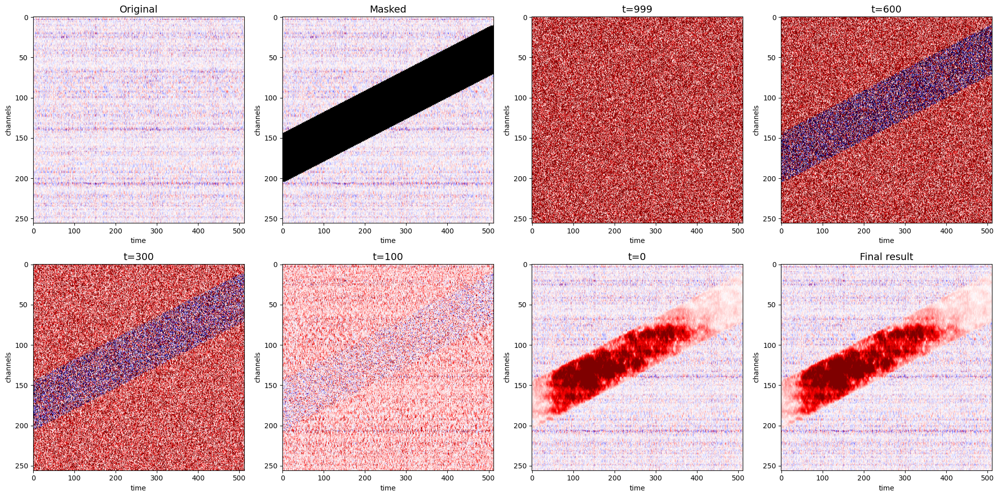

In [100]:
steps_to_show = [999, 600, 300, 100, 0]

patch_denorm_n = denormalize(patch_n)
masked_denorm_n1 = denormalize(masked_patch_n1)
result_denorm_n1 = denormalize(result_n1)

fig, axes = plt.subplots(2,4,figsize=(20, 10))
axes = axes.flatten()
axes[0].imshow(patch_denorm_n[0,0].detach().cpu(),cmap="seismic",aspect="auto",vmin=vmin_n,vmax=vmax_n)
axes[0].set_title("Original", fontsize=14)

axes[1].imshow(masked_denorm_n1[0,0].detach().cpu(),cmap="seismic",aspect="auto",vmin=vmin_n,vmax=vmax_n)

axes[1].imshow(missing_region0,cmap="gray_r",aspect="auto",alpha=missing_region0.float())

axes[1].set_title("Masked", fontsize=14)

for i, step in enumerate(snaps_n1):

    snap_denorm_n = denormalize(snaps_n1[step])

    axes[i+2].imshow(snap_denorm_n[0,0].detach().cpu(),cmap="seismic",aspect="auto",vmin=vmin_n,vmax=vmax_n)

    axes[i+2].set_title(f"t={step}",fontsize=14)

axes[7].imshow(result_denorm_n1[0,0].detach().cpu(),cmap="seismic",aspect="auto",vmin=vmin_n,vmax=vmax_n)

axes[7].set_title("Final result",fontsize=14)

for ax in axes:
    ax.set_xlabel("time")
    ax.set_ylabel("channels")

plt.tight_layout()
plt.show()

In [104]:
mask_n2 = line_mask(h=256, w=512, s=(0,175), e=(510,40), r=20, device=device)
masked_patch_n2 = patch_n * mask_n2

In [107]:
seed = 42
torch.manual_seed(seed)
torch.cuda.manual_seed_all(seed)
result_n2, snaps_n2, times_n2 = repaint.sample_repaint(model=model_mb, scheduler=scheduler_E, x0=patch_n, mask=mask_n2,
                                                 jump_length=1, jump_n_sample=3, steps_to_save=[999, 600, 300, 100, 0])

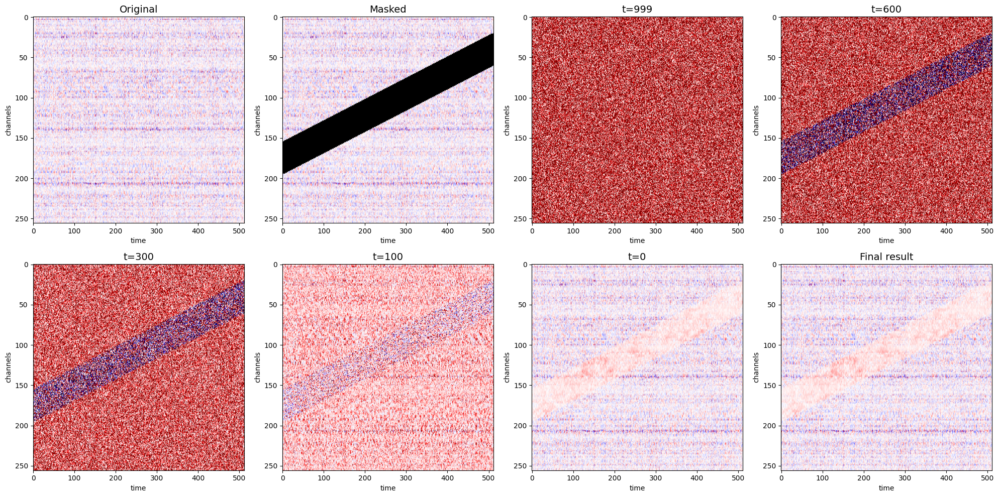

In [108]:
steps_to_show = [999, 600, 300, 100, 0]

patch_denorm_n = denormalize(patch_n)
masked_denorm_n2 = denormalize(masked_patch_n2)
result_denorm_n2 = denormalize(result_n2)
missing_region_n2 = (mask_n2 == 0).detach().cpu()

fig, axes = plt.subplots(2,4,figsize=(20, 10))
axes = axes.flatten()
axes[0].imshow(patch_denorm_n[0,0].detach().cpu(),cmap="seismic",aspect="auto",vmin=vmin_n,vmax=vmax_n)
axes[0].set_title("Original", fontsize=14)

axes[1].imshow(masked_denorm_n2[0,0].detach().cpu(),cmap="seismic",aspect="auto",vmin=vmin_n,vmax=vmax_n)

axes[1].imshow(missing_region_n2,cmap="gray_r",aspect="auto",alpha=missing_region_n2.float())

axes[1].set_title("Masked", fontsize=14)

for i, step in enumerate(snaps_n2):

    snap_denorm_n2 = denormalize(snaps_n2[step])

    axes[i+2].imshow(snap_denorm_n2[0,0].detach().cpu(),cmap="seismic",aspect="auto",vmin=vmin_n,vmax=vmax_n)

    axes[i+2].set_title(f"t={step}",fontsize=14)

axes[7].imshow(result_denorm_n2[0,0].detach().cpu(),cmap="seismic",aspect="auto",vmin=vmin_n,vmax=vmax_n)

axes[7].set_title("Final result",fontsize=14)

for ax in axes:
    ax.set_xlabel("time")
    ax.set_ylabel("channels")

plt.tight_layout()
plt.show()